# Praktikum P5 — Object Detection Rock Paper Scissors (YOLOv8n)

Notebook lengkap berdasarkan alur **P5 Object Detection** dan eksperimen yang sudah kamu lakukan di `Untitled0.ipynb`.

**Alur:** instalasi → persiapan lingkungan → unduh dataset → periksa anotasi → load model → training opsional → pilih `best.pt` → validasi → inference → uji confidence threshold → error analysis.

> **Catatan lokal:** Notebook menggunakan dataset di `C:/Project_Comvis/rock-paper-scissors-1` dan bobot di `C:/Project_Comvis/YOLOv8/best.pt`. Jalankan cell dari atas ke bawah. Output evaluasi yang tersimpan berasal dari eksekusi sebelumnya; jalankan ulang untuk memperoleh hasil dari lingkungan lokal.


## 1. Install library dan persiapan lingkungan (P5 Step 1?2)

Notebook tidak mengimpor atau memanggil `torch` secara langsung. Ultralytics tetap menggunakan PyTorch sebagai dependensi internal untuk model YOLO berformat `.pt`; instalasi `ultralytics` akan memasang dependensi yang dibutuhkan.


In [1]:
%pip install ultralytics pyyaml pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached ultralytics-8.4.176-py3-none-any.whl.metadata (46 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached torch-2.14.1-cp312-cp312-win_amd64.whl.metadata (38 kB)
  Using cached torchvision-0.29.1-cp312-cp312-win_amd64.whl.metadata (5.7 kB)
  Using cached ultralytics_thop-2.2.2-py3-none-any.whl.metadata (14 kB)
  Using cached ultralytics_platform-0.1.84-py3-none-any.whl.metadata (17 kB)
  Using cached filelock-4.1.1-py3-none-any.whl.metadata (2.0 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
  Using cached h11-0.16.0-py3-


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, glob, shutil, random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import yaml
import matplotlib.pyplot as plt
import ultralytics
from ultralytics import YOLO

print('Ultralytics:', ultralytics.__version__)
print('Library siap. Perangkat komputasi dikelola oleh Ultralytics saat model dijalankan.')


Ultralytics: 8.4.176
Library siap. Perangkat komputasi dikelola oleh Ultralytics saat model dijalankan.


## 2. Dataset lokal dan anotasi (P5 Step 4)

Dataset Roboflow RPS versi 1 sudah tersedia di `C:/Project_Comvis/rock-paper-scissors-1`. Cell berikut membaca dataset lokal dan membuat `YOLOv8/data.local.yaml` dengan path absolut untuk train, validation, dan test. Tidak diperlukan download atau API key.


In [4]:
from pathlib import Path
import yaml

PROJECT_DIR = Path(r"C:\Project_Comvis")
MODEL_DIR = PROJECT_DIR / "YOLOv8"
dataset_dir = PROJECT_DIR / "rock-paper-scissors-1"
source_yaml_path = dataset_dir / "data.yaml"

if not source_yaml_path.is_file():
    raise FileNotFoundError(f"Konfigurasi dataset tidak ditemukan: {source_yaml_path}")

# Gunakan path absolut agar dataset dapat dibaca dari folder kerja mana pun.
with source_yaml_path.open(encoding="utf-8") as f:
    local_config = yaml.safe_load(f)
local_config["path"] = dataset_dir.as_posix()
for key, split in [("train", "train"), ("val", "valid"), ("test", "test")]:
    image_dir = dataset_dir / split / "images"
    if not image_dir.is_dir():
        raise FileNotFoundError(f"Folder gambar tidak ditemukan: {image_dir}")
    local_config[key] = image_dir.as_posix()

# Simpan konfigurasi lokal terpisah; data.yaml asli tetap tersedia.
yaml_path = MODEL_DIR / "data.local.yaml"
with yaml_path.open("w", encoding="utf-8") as f:
    yaml.safe_dump(local_config, f, allow_unicode=True, sort_keys=False)

print("Folder dataset:", dataset_dir)
print("Konfigurasi lokal:", yaml_path)


Folder dataset: C:\Project_Comvis\rock-paper-scissors-1
Konfigurasi lokal: C:\Project_Comvis\YOLOv8\data.local.yaml


In [5]:
with open(yaml_path, 'r', encoding='utf-8') as f:
    dataset_config = yaml.safe_load(f)
print('Konfigurasi YAML:')
print(yaml.safe_dump(dataset_config, allow_unicode=True, sort_keys=False))

rows = []
for split in ['train','valid','test']:
    imgdir = dataset_dir / split / 'images'
    labdir = dataset_dir / split / 'labels'
    images = [p for p in imgdir.glob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}] if imgdir.exists() else []
    labels = list(labdir.glob('*.txt')) if labdir.exists() else []
    object_count = sum(len([line for line in p.read_text(errors='replace').splitlines() if line.strip()]) for p in labels)
    rows.append({'Split':split,'Jumlah gambar':len(images),'File label':len(labels),'Objek anotasi':object_count})
display(pd.DataFrame(rows))
print('Catatan: 1 file label bisa berisi lebih dari 1 anotasi objek.')

Konfigurasi YAML:
names:
- Paper
- Rock
- Scissors
nc: 3
roboflow:
  license: Private
  project: rock-paper-scissors-sxsw
  url: https://universe.roboflow.com/roboflow-58fyf/rock-paper-scissors-sxsw/dataset/1
  version: 1
  workspace: roboflow-58fyf
test: C:/Project_Comvis/rock-paper-scissors-1/test/images
train: C:/Project_Comvis/rock-paper-scissors-1/train/images
val: C:/Project_Comvis/rock-paper-scissors-1/valid/images
path: C:/Project_Comvis/rock-paper-scissors-1



,Split,Jumlah gambar,File label,Objek anotasi
0,train,784,784,571
1,valid,224,224,169
2,test,121,121,94


Catatan: 1 file label bisa berisi lebih dari 1 anotasi objek.


### Interpretasi dataset

Output tersimpan menunjukkan **1.129 gambar**: 784 train (69,44%), 224 validation (19,84%), dan 121 test (10,72%). Train digunakan untuk belajar, validation untuk mengevaluasi dan memilih model, sedangkan test untuk menilai kemampuan pada data yang tidak digunakan selama pelatihan/pemilihan model.

Terdapat 571, 169, dan 94 objek beranotasi pada masing-masing split. Jumlah file label yang sama dengan jumlah gambar tidak berarti semua gambar memiliki objek: log validasi mencatat **61 background** dan log test **27 background**, yaitu gambar tanpa anotasi objek. Gambar ini dapat membantu menguji deteksi berlebih, tetapi perlu diperiksa secara visual untuk memastikan bukan anotasi tangan yang terlewat. Jumlah objek per kelas perlu diperhatikan; jumlah gambar saja belum membuktikan keseimbangan kelas.


### Contoh anotasi YOLO

Format satu baris `.txt`: `class_id x_center y_center width height`. Posisi dan ukuran bounding box dinormalisasi 0–1. Kode berikut menunjukkan file anotasi dan gambar contoh yang sudah dianotasi.

Contoh gambar: 20220216_220815_jpg.rf.b868f004f96d31fdf1918bd29d0315e9.jpg
Contoh label: 20220216_220815_jpg.rf.b868f004f96d31fdf1918bd29d0315e9.txt
2 0.5027654867256637 0.7182835820895522 0.4944690265486726 0.2332089552238806


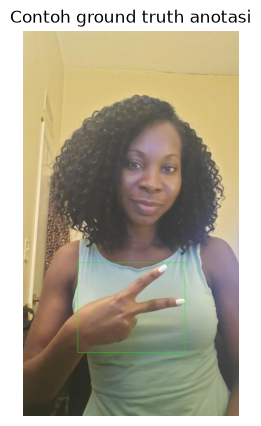

In [6]:
train_images = sorted([p for p in (dataset_dir/'train'/'images').glob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}])
assert train_images, 'Folder train/images kosong'
sample_image = train_images[0]
sample_label = dataset_dir/'train'/'labels'/(sample_image.stem + '.txt')
print('Contoh gambar:', sample_image.name)
print('Contoh label:', sample_label.name)
print(sample_label.read_text()[:1200] if sample_label.exists() else 'File anotasi tidak ditemukan')

im = cv2.cvtColor(cv2.imread(str(sample_image)), cv2.COLOR_BGR2RGB)
h, w = im.shape[:2]
canvas = im.copy()
for line in (sample_label.read_text().splitlines() if sample_label.exists() else []):
    parts = line.strip().split()
    if len(parts) < 5: continue
    cls,xc,yc,bw,bh = map(float, parts[:5])
    x1,y1 = int((xc-bw/2)*w),int((yc-bh/2)*h)
    x2,y2 = int((xc+bw/2)*w),int((yc+bh/2)*h)
    cv2.rectangle(canvas,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(canvas,str(int(cls)),(x1,max(18,y1-4)),cv2.FONT_HERSHEY_SIMPLEX,.6,(0,255,0),2)
plt.figure(figsize=(7,5));plt.imshow(canvas);plt.axis('off');plt.title('Contoh ground truth anotasi');plt.show()

### Interpretasi contoh anotasi

Label contoh memiliki `class_id=2`, yaitu **Scissors**, dengan pusat box sekitar (0,503; 0,718), lebar 0,494 dan tinggi 0,233 relatif terhadap ukuran gambar. Artinya, pusat objek berada dekat tengah secara horizontal dan di bagian bawah gambar. Nilai tersebut adalah koordinat relatif, bukan confidence. Ketepatan anotasi menjadi acuan penilaian posisi dan kelas hasil deteksi.


## 3. Load model dan training (P5 Step 3 & 5)

**Pilih salah satu:**
- `TRAIN_AGAIN = False` (default): gunakan bobot `best.pt` lama, **tanpa training ulang**. Bobot dibaca dari `C:/Project_Comvis/YOLOv8/best.pt`.
- `TRAIN_AGAIN = True`: latih ulang memakai **15 epoch**, seperti notebook awal kamu; training baru bisa memakan waktu cukup lama pada CPU.

Parameter `patience=5` ditambahkan sesuai penjelasan *early stopping* di PPT, sedangkan `epochs=15` mengikuti eksperimenmu.

In [7]:
from ultralytics import YOLO

TRAIN_AGAIN = False  # Gunakan best.pt tanpa training ulang.
BEST_PT_PATH = MODEL_DIR / "best.pt"

if TRAIN_AGAIN:
    model = YOLO(str(MODEL_DIR / "yolov8n.pt"))
    results = model.train(
        data=str(yaml_path),
        epochs=15,
        imgsz=640,
        batch=8,
        patience=5,
        project=str(MODEL_DIR / "runs" / "detect"),
        name="rps_yolov8n",
        exist_ok=False,
    )
    best_path = Path(model.trainer.best)
else:
    best_path = BEST_PT_PATH
    if not best_path.is_file():
        raise FileNotFoundError(f"Bobot model tidak ditemukan: {best_path}")

model = YOLO(str(best_path))
print("Model yang digunakan:", best_path)
print("Daftar kelas:", model.names)


Model yang digunakan: C:\Project_Comvis\YOLOv8\best.pt
Daftar kelas: {0: 'Paper', 1: 'Rock', 2: 'Scissors'}


## 4. Early stopping dan output training (P5 Step 6–7)

Pada proses training, amati `box_loss`, `cls_loss`, `dfl_loss`, Precision, Recall, mAP. `best.pt` adalah bobot performa validasi terbaik; `last.pt` bobot epoch terakhir. Jika kamu menggunakan model lama, output training historis tidak otomatis tersedia di runtime ini.

In [8]:
print('Bobot yang dipakai:', best_path)
for p in sorted(best_path.parent.glob('*.pt')):
    print('-',p.name)
results_csv = best_path.parent.parent / 'results.csv'
if results_csv.exists():
    history = pd.read_csv(results_csv)
    display(history.tail())
else:
    print('results.csv tidak ada pada runtime ini. Cek output training di notebook lama.')

Bobot yang dipakai: C:\Project_Comvis\YOLOv8\best.pt
- best.pt
results.csv tidak ada pada runtime ini. Cek output training di notebook lama.


### Interpretasi model dan riwayat pelatihan

Eksekusi tersimpan menggunakan bobot **best.pt** yang sudah tersedia (`TRAIN_AGAIN=False`). Karena itu, konfigurasi 15 epoch dan `patience=5` pada cabang training adalah pengaturan untuk pelatihan ulang, bukan bukti bahwa eksekusi ini melakukan training selama 15 epoch atau mengalami early stopping.

File `results.csv` tidak tersedia pada output ini. Tren loss, epoch terbaik, konvergensi, serta overfitting selama training belum dapat disimpulkan. Log evaluasi menunjukkan model dengan sekitar **3,13 juta parameter**. Pada CPU yang tercatat, waktu inferensi validasi 195,3 ms/gambar setara sekitar 5,1 gambar/detik untuk inferensi saja; ini belum mengukur FPS aplikasi webcam lengkap.


## 5. Evaluation / Validation (P5 Step 7 — Evaluation)

In [9]:
metrics = model.val(data=str(yaml_path), split='val', imgsz=640, batch=8, plots=True, project=str(MODEL_DIR / 'runs' / 'detect'))
print(f'Precision : {metrics.box.mp:.4f}')
print(f'Recall    : {metrics.box.mr:.4f}')
print(f'mAP@50    : {metrics.box.map50:.4f}')
print(f'mAP@50-95 : {metrics.box.map:.4f}')
print(f'mAP@75    : {metrics.box.map75:.4f}')
print('Folder hasil evaluasi:', metrics.save_dir)

Ultralytics 8.4.176  Python-3.12.4 torch-2.14.1+cpu CPU (AMD Ryzen 7 5825U with Radeon Graphics)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.0 ms, read: 2.2±0.4 MB/s, size: 19.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Project_Comvis\rock-paper-scissors-1\valid\labels... 224 images, 61 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 224/224 671.5it/s 0.3s0.0s
val: New cache created: C:\Project_Comvis\rock-paper-scissors-1\valid\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 28/28 1.9it/s 14.9s0.6s
                   all        224        169      0.989      0.917      0.961      0.663
                 Paper         58         61      0.982      0.885       0.92      0.627
                  Rock         58         61 

### Interpretasi hasil validasi

Evaluasi menggunakan **224 gambar dengan 169 objek**. Nilai berikut berasal dari output tersimpan, bukan hasil eksekusi ulang.

| Metrik | Nilai | Interpretasi |
|---|---:|---|
| Precision | 98,94% | Rata-rata precision kelas tinggi; prediksi yang diterima pada titik evaluasi relatif jarang salah. |
| Recall | 91,66% | Sebagian objek masih terlewat; recall lebih rendah daripada precision. |
| mAP@50 | 96,10% | Kemampuan deteksi tinggi pada kriteria kecocokan box IoU 0,50. |
| mAP@75 | 82,06% | Kinerja menurun ketika kecocokan posisi box harus lebih ketat. |
| mAP@50-95 | 66,32% | Rata-rata AP pada IoU 0,50 sampai 0,95 menunjukkan lokalisasi box masih perlu diperbaiki. |

Selisih mAP@50 dan mAP@50-95 sebesar **29,78 poin persentase** menunjukkan model lebih berhasil pada kriteria box yang longgar daripada yang ketat. mAP bukan persentase gambar yang seluruh prediksinya benar. Precision dan recall yang dilaporkan merupakan rata-rata kelas, sehingga tidak tepat langsung mengalikannya dengan 169 untuk memperoleh jumlah TP/FP/FN. Nilai ini juga tidak otomatis berlaku pada threshold inference 0,25.

| Kelas | Objek | Precision | Recall | AP@50 | AP@50-95 |
|---|---:|---:|---:|---:|---:|
| Paper | 61 | 98,2% | 88,5% | 92,0% | 62,7% |
| Rock | 61 | 100,0% | 90,7% | 96,9% | 66,1% |
| Scissors | 47 | 98,7% | 95,7% | 99,4% | 70,1% |

**Scissors** memiliki recall dan AP tertinggi pada validasi. **Paper** memiliki recall dan AP terendah sehingga menjadi prioritas pemeriksaan objek yang terlewat dan kualitas box. Precision Rock 100% hanya berlaku pada evaluasi ini, bukan jaminan tidak pernah salah pada data baru.


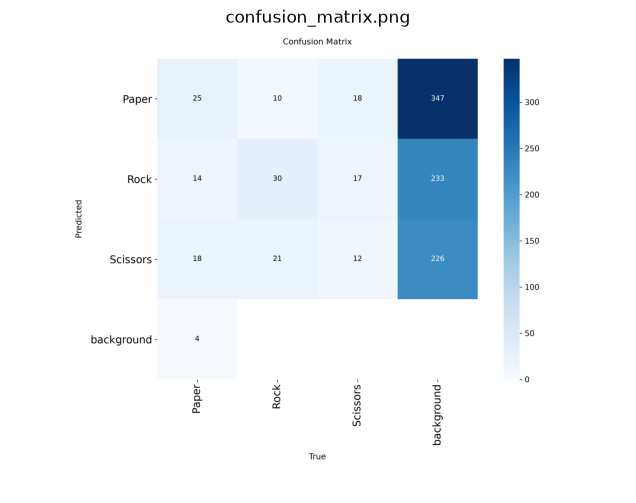

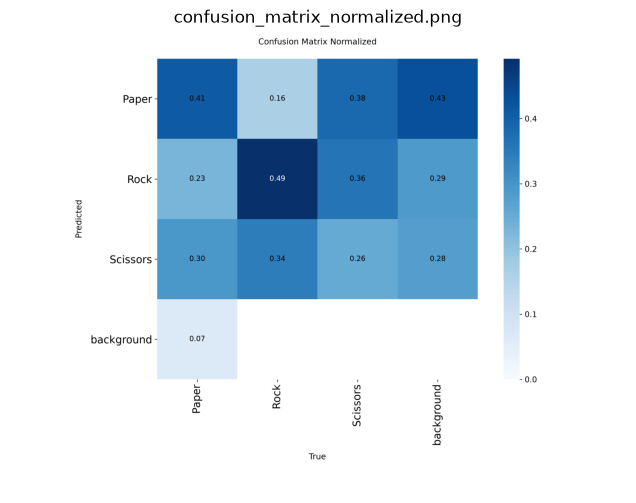

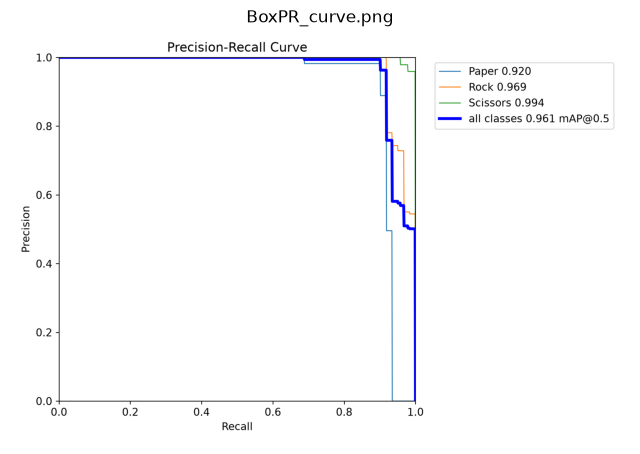

In [11]:
# Visualisasi confusion matrix dan PR curve jika ada
val_dir = Path(metrics.save_dir)
for pattern in ['confusion_matrix.png','confusion_matrix_normalized.png','BoxPR_curve.png']:
    p = val_dir / pattern
    if p.exists():
        plt.figure(figsize=(8,6))
        plt.imshow(plt.imread(p));plt.axis('off');plt.title(p.name);plt.show()
    else:
        print('Tidak ditemukan:', pattern)

### Interpretasi grafik dan konsistensi output

Kurva precision-recall mencantumkan AP Paper 0,920, Rock 0,969, Scissors 0,994, serta mAP 0,961; angka ini selaras dengan tabel validasi. Kurva menunjukkan precision tinggi pada sebagian besar rentang recall, lalu menurun saat lebih banyak deteksi diterima.

**Namun, confusion matrix tersimpan tidak selaras dengan ringkasan metrik.** Dengan sumbu horizontal kelas sebenarnya dan vertikal prediksi, diagonalnya hanya 25 Paper, 30 Rock, dan 12 Scissors. Kolom background menunjukkan 347 prediksi Paper, 233 Rock, dan 226 Scissors tanpa pasangan ground truth. Pola tersebut tidak mendukung pembacaan bahwa hampir seluruh deteksi benar.

Perbedaan threshold, pengaturan evaluasi, atau artefak dari eksekusi berbeda perlu diperiksa; penyebabnya belum dapat dipastikan dari notebook ini. Jalankan ulang evaluasi dan visualisasi secara berurutan dengan bobot, split, serta folder hasil yang sama sebelum menggunakan confusion matrix untuk menghitung atau menjelaskan kesalahan model. Analisis angka di atas mengikuti log metrik tersimpan dan masih memerlukan pemeriksaan konsistensi ini.


## 6. Inference pada gambar validation (P5 Step 8)

Jumlah objek terdeteksi: 2


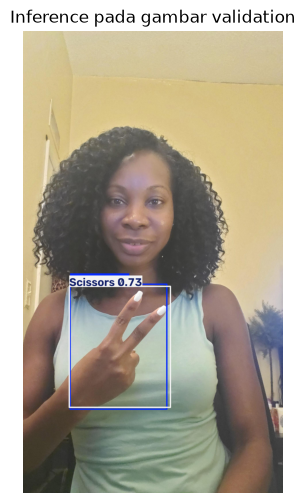

In [10]:
image_path = str(train_images[0])
valid_images = sorted([p for p in (dataset_dir/'valid'/'images').glob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}])
if valid_images:
    image_path = str(valid_images[0])
result = model.predict(source=image_path, conf=0.25, iou=0.45, verbose=False)[0]
print('Jumlah objek terdeteksi:',len(result.boxes))
plt.figure(figsize=(9,6))
plt.imshow(cv2.cvtColor(result.plot(),cv2.COLOR_BGR2RGB))
plt.axis('off');plt.title('Inference pada gambar validation');plt.show()

## 7. Eksperimen confidence threshold (P5 Step 9)

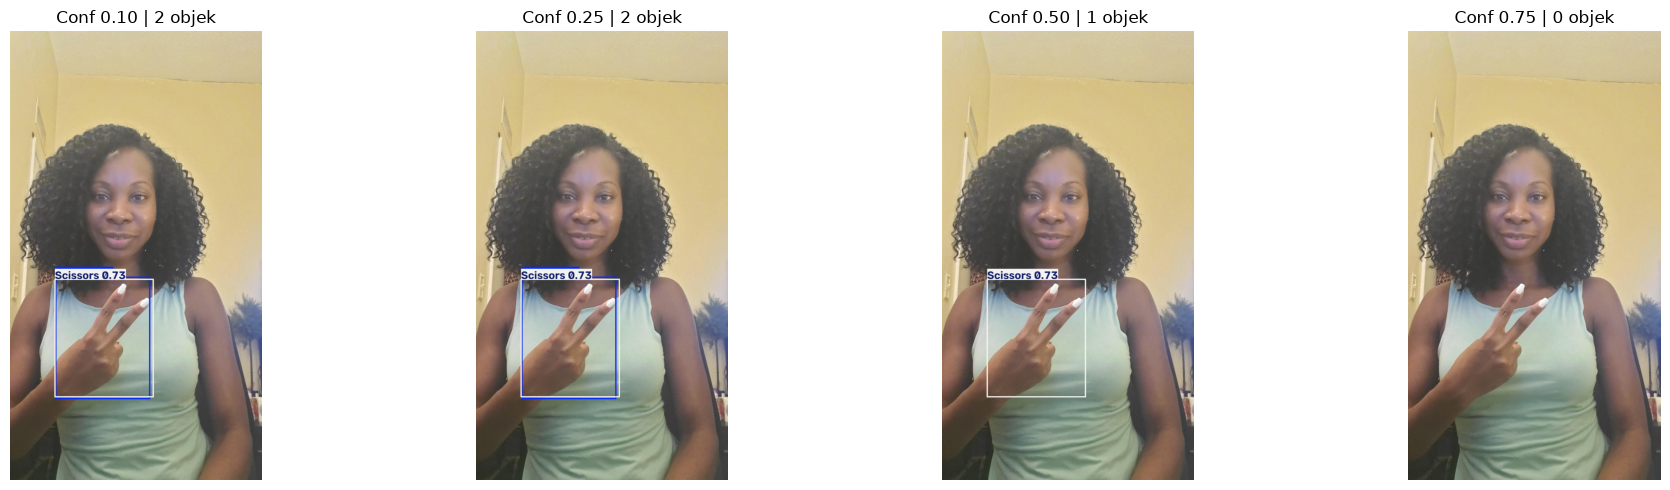

,Confidence threshold,Jumlah deteksi
0,0.10,2
1,0.25,2
2,0.50,1
3,0.75,0


Gunakan gambar yang sama untuk semua threshold agar perbandingan adil.


In [12]:
thresholds = [0.10,0.25,0.50,0.75]
threshold_results = []
fig, axes = plt.subplots(1,4,figsize=(20,5))
for ax,t in zip(axes,thresholds):
    r = model.predict(source=image_path,conf=t,iou=0.45,verbose=False)[0]
    threshold_results.append({'Confidence threshold':t,'Jumlah deteksi':len(r.boxes)})
    ax.imshow(cv2.cvtColor(r.plot(),cv2.COLOR_BGR2RGB))
    ax.set_title(f'Conf {t:.2f} | {len(r.boxes)} objek');ax.axis('off')
plt.tight_layout();plt.show()
display(pd.DataFrame(threshold_results))
print('Gunakan gambar yang sama untuk semua threshold agar perbandingan adil.')

### Interpretasi eksperimen confidence threshold

| Threshold | Jumlah deteksi tersimpan | Interpretasi |
|---|---:|---|
| 0,10 | 2 | Lebih banyak kandidat lolos; kandidat berconfidence rendah perlu diperiksa. |
| 0,25 | 2 | Jumlah deteksi tetap sama pada contoh ini. |
| 0,50 | 1 | Satu kandidat tersaring ketika threshold dinaikkan. |
| 0,75 | 0 | Seluruh kandidat tersaring; objek beranotasi pada gambar ini tidak terdeteksi pada threshold tersebut. |

Berdasarkan tabel, satu kandidat tersaring antara threshold 0,25 dan 0,50, sedangkan kandidat lainnya tersaring antara 0,50 dan 0,75. Menaikkan threshold dapat mengurangi deteksi yang salah, tetapi juga membuang deteksi yang benar. Confidence bukan ukuran ketepatan posisi box dan bukan jaminan prediksi benar.

Hasil satu gambar belum cukup untuk menetapkan threshold terbaik. Bandingkan precision, recall, dan F1 pada seluruh validation set untuk setiap threshold dengan aturan pencocokan kelas/IoU yang sama. Pilih threshold dari validation set, kemudian nilai konfigurasi terpilih pada test set. Kesimpulan tabel ini mengikuti teks output tersimpan; konsistensi dengan gambar perlu diperiksa seperti pada bagian error analysis.


## 8. Error Analysis (P5 Step 10)

Tahap ini fokus pada **kesalahan**, bukan hanya metrik. Contoh di bawah menggunakan **satu gambar yang sama** dan membandingkan anotasi ground truth dengan hasil prediksi. Amati kemungkinan:
- **False positive:** prediksi muncul padahal tidak ada objek yang cocok.
- **False negative:** ada objek beranotasi yang tidak ditemukan.
- **Localization error:** posisi/ukuran box kurang tepat.
- **Classification error:** kelas hasil prediksi salah.
- **Low-confidence detection:** objek tersaring jika threshold dinaikkan.

Penilaian otomatis atas FP/FN perlu pencocokan prediksi dan ground truth dengan IoU; visualisasi di bawah adalah **bahan analisis manual**, bukan hitungan FP/FN otomatis.

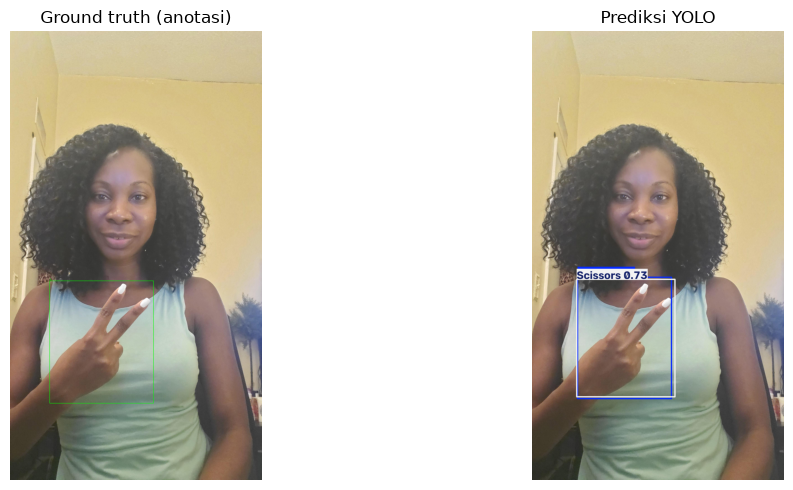

Objek ground truth: 1
Jumlah prediksi: 2
Analisis manual: adakah box terlewat, salah kelas, box kurang tepat, atau deteksi berlebih?


In [13]:
analysis_img = valid_images[0] if valid_images else train_images[0]
analysis_split = 'valid' if valid_images else 'train'
analysis_label = dataset_dir/analysis_split/'labels'/(analysis_img.stem+'.txt')
base = cv2.cvtColor(cv2.imread(str(analysis_img)),cv2.COLOR_BGR2RGB)
h,w = base.shape[:2]
gt = base.copy()
for line in (analysis_label.read_text().splitlines() if analysis_label.exists() else []):
    parts=line.strip().split()
    if len(parts)<5:continue
    cls,xc,yc,bw,bh=map(float,parts[:5])
    x1,y1=int((xc-bw/2)*w),int((yc-bh/2)*h)
    x2,y2=int((xc+bw/2)*w),int((yc+bh/2)*h)
    cv2.rectangle(gt,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(gt,str(int(cls)),(x1,max(20,y1-4)),cv2.FONT_HERSHEY_SIMPLEX,.5,(0,255,0),2)
r = model.predict(source=str(analysis_img),conf=0.25,verbose=False)[0]
pred=cv2.cvtColor(r.plot(),cv2.COLOR_BGR2RGB)
fig,axs=plt.subplots(1,2,figsize=(13,5))
axs[0].imshow(gt);axs[0].set_title('Ground truth (anotasi)');axs[0].axis('off')
axs[1].imshow(pred);axs[1].set_title('Prediksi YOLO');axs[1].axis('off')
plt.tight_layout();plt.show()
print('Objek ground truth:',len(analysis_label.read_text().splitlines()) if analysis_label.exists() else 'label tidak ada')
print('Jumlah prediksi:',len(r.boxes))
print('Analisis manual: adakah box terlewat, salah kelas, box kurang tepat, atau deteksi berlebih?')

### Interpretasi kesalahan pada gambar contoh

Ground truth menandai satu tangan dengan gestur **Scissors**. Pada visualisasi prediksi tersimpan tampak **satu box Scissors dengan confidence 0,73**, dan posisinya secara visual mendekati box ground truth. Ini menunjukkan kecocokan kelas secara visual, tetapi nilai IoU belum dihitung sehingga kecocokan kuantitatif belum dapat dipastikan.

Teks output justru menyebut **1 objek ground truth dan 2 prediksi**. Dengan pencocokan satu-ke-satu, jika dua prediksi tersebut benar-benar berasal dari eksekusi yang sama, paling banyak satu dapat dipasangkan dengan satu ground truth dan sedikitnya satu prediksi tidak mendapat pasangan. Namun, gambar yang ditampilkan tidak cukup untuk mengidentifikasi prediksi tambahan tersebut. Jangan menyatakan lokasi atau kelas false positive tanpa memeriksa box aslinya.

Jalankan ulang cell inference, threshold, dan error analysis secara berurutan; samakan confidence dan IoU NMS (inference memakai `iou=0.45`, sedangkan error analysis belum menetapkannya secara eksplisit). Tampilkan kelas, confidence, koordinat tiap box, lalu cocokkan dengan ground truth berdasarkan kelas dan IoU untuk menentukan TP, FP, FN, serta kesalahan lokalisasi secara terukur. IoU untuk NMS dan IoU untuk pencocokan evaluasi memiliki fungsi berbeda.


## 9. Evaluasi pada test set (tambahan untuk tugas Latihan)

PPT menekankan metrik evaluasi dan contoh inference; pengujian pada `test` disediakan sebagai tambahan jika folder test memang tersedia. Jangan menyamakan metrik validation dengan test.

In [14]:
if (dataset_dir/'test'/'images').exists() and any((dataset_dir/'test'/'images').iterdir()):
    test_metrics=model.val(data=str(yaml_path),split='test',imgsz=640,batch=8,plots=True, project=str(MODEL_DIR / 'runs' / 'detect'))
    print(f'TEST Precision: {test_metrics.box.mp:.4f}')
    print(f'TEST Recall: {test_metrics.box.mr:.4f}')
    print(f'TEST mAP@50: {test_metrics.box.map50:.4f}')
    print(f'TEST mAP@50-95: {test_metrics.box.map:.4f}')
else:
    print('Folder test tidak tersedia; tahap test dilewati.')

Ultralytics 8.4.176  Python-3.12.4 torch-2.14.1+cpu CPU (AMD Ryzen 7 5825U with Radeon Graphics)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.1±0.2 ms, read: 4.1±3.7 MB/s, size: 45.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Project_Comvis\rock-paper-scissors-1\test\labels... 121 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 121/121 558.7it/s 0.2s0.0s
val: New cache created: C:\Project_Comvis\rock-paper-scissors-1\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 2.0it/s 8.1s0.5s
                   all        121         94      0.867      0.887       0.91      0.612
                 Paper         40         40      0.881       0.85      0.884      0.549
                  Rock         25         25    

### Interpretasi test dan perbandingan dengan validasi

Test set berisi **121 gambar dengan 94 objek beranotasi**. Perbandingan berikut memakai nilai ringkasan empat desimal yang tersimpan.

| Metrik | Validation | Test | Penurunan (poin persentase) |
|---|---:|---:|---:|
| Precision | 98,94% | 86,73% | 12,21 |
| Recall | 91,66% | 88,70% | 2,96 |
| mAP@50 | 96,10% | 90,95% | 5,15 |
| mAP@50-95 | 66,32% | 61,22% | 5,10 |

Seluruh metrik test lebih rendah. Penurunan precision paling besar menunjukkan prediksi pada test lebih rentan salah pada titik evaluasi yang dilaporkan. Selisih ini dapat berkaitan dengan variasi gambar, komposisi kelas, ukuran sampel, atau kemampuan generalisasi; tanpa riwayat training dan pemeriksaan data, selisih tersebut belum membuktikan overfitting.

Pada test, **Rock** memiliki precision terendah (79,8%) sehingga prediksi Rock menjadi prioritas pemeriksaan false positive. **Paper** memiliki recall terendah (85,0%) dan AP@50-95 terendah (54,9%), sehingga objek yang terlewat dan kualitas lokalisasinya perlu diperiksa. **Scissors** tetap memiliki AP tertinggi (AP@50 94,9%; AP@50-95 67,3%). Komposisi objek test adalah 40 Paper, 25 Rock, dan 29 Scissors; hasil pada sampel ini belum mewakili seluruh kondisi kamera.

Kesimpulan generalisasi ini mengasumsikan test tidak digunakan untuk training atau pemilihan model, serta tidak memiliki kebocoran/duplikasi dengan train. Asumsi tersebut belum diaudit dalam notebook.


## 10. Lokasi best.pt untuk aplikasi webcam

Bobot sudah tersedia secara lokal. Gunakan lokasi yang ditampilkan cell berikut pada program webcam.


In [15]:
# Bobot sudah tersedia di komputer, tidak perlu diunduh dari Colab.
print("Lokasi bobot untuk aplikasi webcam:", best_path.resolve())


Lokasi bobot untuk aplikasi webcam: C:\Project_Comvis\YOLOv8\best.pt


## Ringkasan pencapaian tujuh ketentuan latihan halaman 18

1. **Permasalahan:** deteksi gestur Rock, Paper, Scissors dari gambar/kamera.
2. **Dataset:** Roboflow RPS versi 1; karakteristik dan anotasi terukur di bagian 2.
3. **Model:** YOLOv8n; **pastikan berbeda dari kelompok lain**.
4. **Alasan model:** varian nano ringan untuk praktikum dan inferensi webcam; bukan klaim lebih unggul dari semua versi baru.
5. **Eksperimen:** training 15 epoch bila dijalankan, atau pakai bobot lama yang sudah dilatih.
6. **Evaluasi:** metrik validasi dan opsional test di bagian 5 serta 9.
7. **Inference:** contoh bounding box di bagian 6, ditambah demo webcam kamu.

**Penting:** Simpan screenshot output hasil eksekusi dan tulis analisis angka yang benar-benar muncul. Nilai metrik notebook lama tidak otomatis sama dengan hasil run yang baru.

## Kesimpulan analisis

Berdasarkan log evaluasi tersimpan, YOLOv8n dengan bobot `best.pt` mampu mendeteksi tiga gestur dengan **mAP@50 validasi 96,10% dan test 90,95%**. Scissors paling kuat berdasarkan AP pada kedua split. Paper perlu perbaikan recall dan lokalisasi, sedangkan prediksi Rock pada test perlu diperiksa karena precision relatif rendah. Penurunan mAP pada kriteria IoU lebih ketat menunjukkan bahwa ketepatan box masih menjadi ruang perbaikan.

Eksperimen threshold memperlihatkan pertukaran antara jumlah deteksi yang diterima dan risiko objek terlewat, tetapi belum menetapkan threshold optimal. Prioritas berikutnya adalah menyelaraskan output evaluasi/grafik, memeriksa anotasi dan kasus salah deteksi, kemudian mengevaluasi threshold pada seluruh validation set. Penambahan variasi data dan penyesuaian training sebaiknya didasarkan pada kesalahan yang sudah terverifikasi.

**Batasan laporan:** interpretasi ini ditambahkan dari output yang sudah tersimpan, tanpa training atau inference ulang. Confusion matrix dan jumlah box pada contoh memiliki ketidaksesuaian yang perlu diselesaikan sebelum hasil dianggap final. Jika notebook dijalankan ulang, perbarui angka dan interpretasi sesuai hasil terbaru.
